# Voice Digits: an end-to-end ML pipeline for spoken digits

**Use case.** My Introduction to ML summative used the FinScope survey to predict who has a bank account in East Africa. The people the models served worst were the ones financial inclusion is meant to reach: rural adults, women, and people with little schooling. Mobile money menus (USSD, apps) assume you can read them. A voice interface lets someone *say* an amount or a phone number instead, one digit at a time.

This notebook builds the part that recognises a single spoken digit (0 to 9) from a short recording. The data is audio, not tabular: two public datasets of people saying the digits zero to nine.

| Step | Where the code lives |
|---|---|
| 1. Data acquisition | `src/data_acquisition.py` |
| 2. Data processing | `src/preprocessing.py` |
| 3. Model creation | `src/model.py` |
| 4. Model testing | `src/model.py` (`evaluate`) and `src/prediction.py` |
| 5. Retraining and its trigger | `src/retrain.py` (used by the API) |

The notebook calls the same functions the API uses, so what is measured here is what runs in production.

In [1]:
import os, sys, json, time, warnings
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
sys.path.insert(0, str(ROOT))
os.chdir(ROOT)
warnings.filterwarnings("ignore")
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import librosa
from IPython.display import Audio, display

from src import config
from src.config import DIGIT_WORDS, SAMPLE_RATE, SEED

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e8e6df", "axes.axisbelow": True,
    "axes.edgecolor": "#b9b7ae", "axes.titleweight": "bold", "font.size": 10,
})
np.random.seed(SEED)
print("project folder:", ROOT)

project folder: C:\Users\user\Documents\voice-digits-pipeline


## 1. Data acquisition

The data is the **Free Spoken Digit Dataset (FSDD)**, version 1.0.10, from GitHub (Jakobovski/free-spoken-digit-dataset, CC BY-SA 4.0). It has 3,000 recordings at 8 kHz: six English speakers each say every digit 50 times. File names carry the label: `7_jackson_32.wav` is the digit 7, said by Jackson, take 32.

`src/data_acquisition.py` downloads the zip and sorts it into three sets:

- **train**: takes 5 to 49 of five speakers (2,250 files)
- **test**: takes 0 to 4 of the same five speakers (250 files), the split the dataset's authors recommend
- **new_voice**: all 500 recordings of the sixth speaker, **george**. The first model never hears this voice. It plays the role of new users who show up after the app is live, and it is the data used to show retraining.

Why george: in a quick leave-one-speaker-out test with a simple MFCC + logistic regression model (accuracy on a speaker the model never trained on), george scored 38%, the lowest of the six (the others: jackson 67%, lucas 48%, nicolas 53%, theo 73%, yweweler 73%). So george is the hardest test of whether retraining helps.

**Why a second dataset.** Six speakers aren't enough. A first version trained on FSDD alone scored 99.6% on its own test set but did badly on a real person's laptop microphone: it rarely answered 4, 5, 6 or 8, and heard most words as 0, 3 or 7. So `src/speech_commands.py` adds the digit words from **Google Speech Commands v0.02** (CC BY 4.0). About 2,600 people recorded these words **through a web browser on their own computers and phones**, the same way the app's Record button works. A sample of 400 clips per digit goes to training, each from a different person where possible, and 100 per digit from the dataset's own test speakers go to the test set. Those test voices are never used in training. File names keep the FSDD pattern: `7_sc-<speaker id>_<take>.wav`. The download also brings real background noise (running tap, dishes, an exercise bike, white and pink noise), which is used to make noisy training copies.

In [2]:
from src.data_acquisition import download, split
from src import speech_commands as sc
counts = split(download(), new_speaker="george")      # FSDD
sc.build(sc.download())                                # + Speech Commands (2.3 GB download, once)

Already downloaded: 3000 files in C:\Users\user\Documents\voice-digits-pipeline\data\raw


new_voice    500 files
test         250 files
train       2250 files


already downloaded: C:\Users\user\Documents\voice-digits-pipeline\data\raw\speech_commands


train [400, 400, 400, 400, 400, 400, 400, 400, 400, 400]
test [100, 100, 100, 100, 100, 100, 100, 100, 100, 100]


120 noise pieces in C:\Users\user\Documents\voice-digits-pipeline\data\noise


In [3]:
from src.preprocessing import list_folder
from src.insights import voice_group
files = pd.DataFrame(
    [dict(r, split=s) for s, d in [("train", config.TRAIN_DIR), ("test", config.TEST_DIR), ("new_voice", config.NEW_VOICE_DIR)]
     for r in list_folder(d)])
files["source"] = np.where(files.speaker.str.startswith("sc-"), "Speech Commands", "FSDD")
files["voice"] = files.speaker.map(voice_group)
print(files.shape, "recordings;", files[files.source == "Speech Commands"].speaker.nunique(), "different Speech Commands speakers")
display(pd.crosstab(files.voice, files.split, margins=True))
display(pd.crosstab([files.split, files.source], files.label))

(8000, 7) recordings; 2104 different Speech Commands speakers


split,new_voice,test,train,All
voice,,,,
george,500,0,0,500
jackson,0,50,450,500
lucas,0,50,450,500
nicolas,0,50,450,500
speech commands,0,1000,4000,5000
theo,0,50,450,500
yweweler,0,50,450,500
All,500,1250,6250,8000


label                        0    1    2    3    4    5    6    7    8    9
split     source                                                           
new_voice FSDD              50   50   50   50   50   50   50   50   50   50
test      FSDD              25   25   25   25   25   25   25   25   25   25
          Speech Commands  100  100  100  100  100  100  100  100  100  100
train     FSDD             225  225  225  225  225  225  225  225  225  225
          Speech Commands  400  400  400  400  400  400  400  400  400  400

Every digit has the same number of recordings in each part (625 training, 125 test), so the classes are balanced. Plain accuracy is a fair score, and no class weights are needed.

Three example recordings: an FSDD training voice, a Speech Commands training voice (a browser recording, so it sounds rougher), and the held-out new voice:

In [4]:
sc_example = sorted(config.TRAIN_DIR.glob("7/7_sc-*.wav"))[0].relative_to(ROOT).as_posix()
for path in ["data/train/7/7_jackson_20.wav", sc_example, "data/new_voice/7/7_george_20.wav"]:
    print(path)
    display(Audio(path))

data/train/7/7_jackson_20.wav


data/train/7/7_sc-019fa366_2.wav


data/new_voice/7/7_george_20.wav


## 2. Data processing

The model needs every input to have the same shape, and it shouldn't care how loud someone speaks or how much silence came before the word. Each recording goes through five steps (`src/preprocessing.py`):

1. **Load** as mono and resample to 8 kHz. Browser and phone recordings are 44.1 or 48 kHz, so they are brought down to the training rate.
2. **Trim silence** at both ends (anything 30 dB below the peak).
3. **Normalise**: divide by the peak, so the loudest sample is 1.
4. **Fix the length** to exactly 1 second (8,000 samples). A short word is centred with silence on both sides. A longer recording keeps its **loudest second**: a microphone recording in a noisy room isn't trimmed much, and cutting its middle second could cut the word.
5. **Log-mel spectrogram**: 40 mel frequency bands × 101 time steps (32 ms window, 10 ms hop), in decibels, scaled to 0..1.

The steps on one recording:

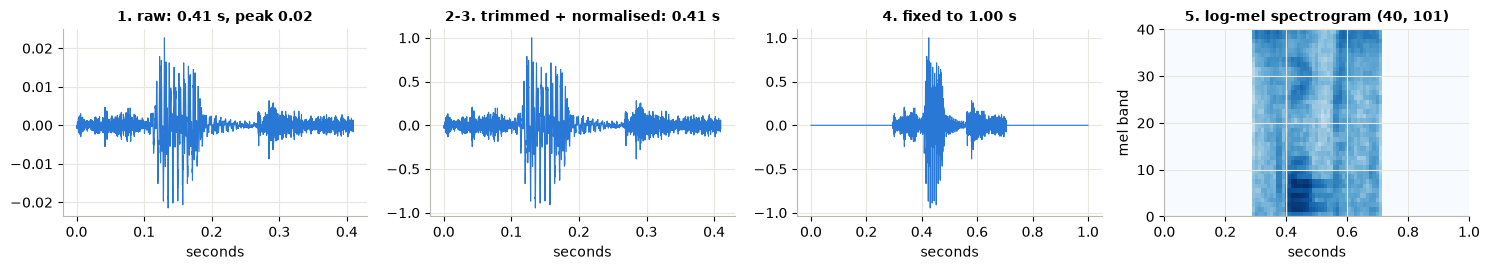

model input shape: (40, 101, 1)  value range: 0.0 to 1.0


In [5]:
from src.preprocessing import load_audio, trim_silence, normalise, fix_length, log_mel, clean

path = "data/train/6/6_theo_20.wav"
raw = load_audio(path)
trimmed = trim_silence(raw)
scaled = normalise(trimmed)
fixed = fix_length(scaled)
spec = log_mel(fixed)

fig, ax = plt.subplots(1, 4, figsize=(15, 2.8))
for a, (y, title) in zip(ax[:3], [(raw, f"1. raw: {len(raw)/SAMPLE_RATE:.2f} s, peak {np.abs(raw).max():.2f}"),
                                  (scaled, f"2-3. trimmed + normalised: {len(scaled)/SAMPLE_RATE:.2f} s"),
                                  (fixed, "4. fixed to 1.00 s")]):
    a.plot(np.arange(len(y)) / SAMPLE_RATE, y, color=BLUE, lw=0.8)
    a.set_title(title, fontsize=10); a.set_xlabel("seconds")
im = ax[3].imshow(spec, origin="lower", aspect="auto", cmap="Blues", extent=[0, 1, 0, 40])
ax[3].set_title(f"5. log-mel spectrogram {spec.shape}", fontsize=10); ax[3].set_xlabel("seconds"); ax[3].set_ylabel("mel band")
plt.tight_layout(); plt.show()
print("model input shape:", spec[..., None].shape, " value range:", spec.min().round(2), "to", spec.max().round(2))

The same function, `prepare()`, runs these five steps for training, bulk uploads and single predictions, so there is no gap between how the model was trained and how it is used.

Files that can't be used are rejected with a reason instead of crashing the app: unreadable files, silent recordings, and recordings longer than 3 seconds (more than one digit).

**Noisy copies for training.** `noisy_inputs()` mixes a random background-noise piece into a clean clip at a random signal-to-noise ratio between 5 and 25 dB, then runs the same steps. Half of the training clips get a noisy copy, so the model also learns words heard in a busy room:

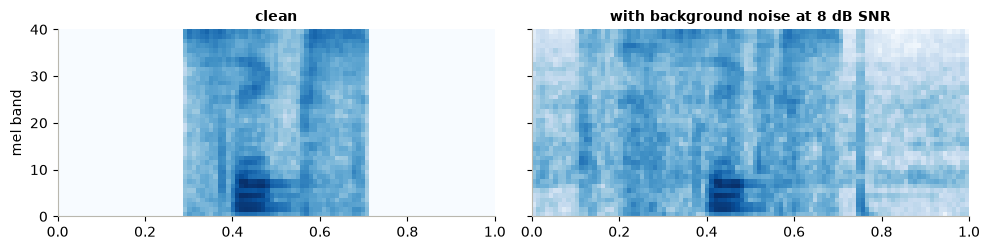

In [6]:
from src.preprocessing import add_noise, normalise
rng = np.random.default_rng(SEED)
clean_clip, _ = clean(load_audio(path))
noisy_clip = normalise(add_noise(clean_clip, rng, snr_db=(8, 8)))
fig, ax = plt.subplots(1, 2, figsize=(10, 2.6), sharey=True)
for a, (y, t) in zip(ax, [(clean_clip, "clean"), (noisy_clip, "with background noise at 8 dB SNR")]):
    a.imshow(log_mel(y), origin="lower", aspect="auto", cmap="Blues", extent=[0, 1, 0, 40]); a.set_title(t, fontsize=10); a.grid(False)
ax[0].set_ylabel("mel band"); plt.tight_layout(); plt.show()

In [7]:
from src.preprocessing import AudioError
for bad, what in [(np.zeros(8000, np.float32), "silence"), (np.random.randn(8000 * 5).astype(np.float32), "5 s of noise")]:
    try:
        clean(bad)
    except AudioError as e:
        print(f"{what:12s} -> rejected: {e}")

silence      -> rejected: the recording is silent
5 s of noise -> rejected: too long (5.0 s); record one digit per file


### Feature visualisations: what the data says

To understand the recordings, `src/insights.py` measures a few simple features on every file. The model doesn't use these; they are for understanding the data:

- **duration**: length of the word after trimming silence
- **zero-crossing rate (ZCR)**: how often the wave crosses zero; high for hissing sounds like *s* and *f*
- **spectral centroid**: the "centre of mass" of the frequencies; high for bright, hissy sounds
- **pitch**: the speaker's voice pitch (median fundamental frequency, YIN algorithm)
- **loudness**: average RMS energy in dB, before normalising

In [8]:
from src.insights import build_features, build_insights
feats = build_features()          # also saved to results/features.csv
_ = build_insights(feats)         # summaries for the web dashboard
feats["word"] = feats.label.map(lambda d: f"{d} {DIGIT_WORDS[d]}")
order = [f"{d} {w}" for d, w in enumerate(DIGIT_WORDS)]
feats.groupby("word")[["duration_s", "zcr", "centroid_hz", "pitch_hz", "rms_db"]].median().round(3).loc[order]

,duration_s,zcr,centroid_hz,pitch_hz,rms_db
word,,,,,
0 zero,0.652,0.136,909.063,128.215,-27.462
1 one,0.576,0.131,830.508,127.686,-28.116
2 two,0.518,0.175,1008.536,148.162,-28.566
3 three,0.576,0.165,1076.021,141.557,-29.100
4 four,0.534,0.167,911.527,136.600,-26.279
5 five,0.576,0.207,1136.320,129.163,-26.453
6 six,0.576,0.316,1520.911,158.557,-32.782
7 seven,0.576,0.190,1096.444,137.193,-28.773
8 eight,0.512,0.207,1260.801,130.423,-28.800


#### Feature 1: duration. Two-syllable digits take the longest

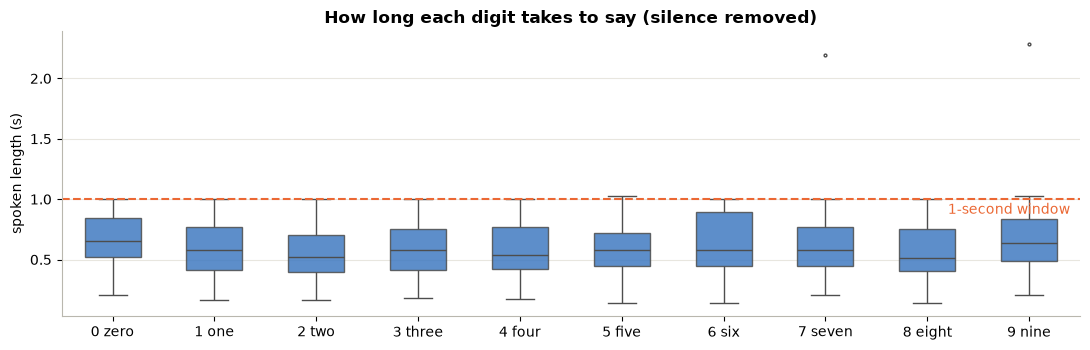

longest: ['zero', 'nine', 'one']  shortest: ['eight', 'two']
recordings longer than 1 s: 5 of 8000


In [9]:
fig, ax = plt.subplots(figsize=(11, 3.6))
sns.boxplot(data=feats, x="word", y="duration_s", order=order, color=BLUE, width=0.55, fliersize=2, linewidth=1, ax=ax,
            boxprops=dict(alpha=0.85))
ax.axhline(1.0, color=ORANGE, lw=1.5, ls="--"); ax.text(9.4, 0.97, "1-second window", color=ORANGE, ha="right", va="top")
ax.set(xlabel="", ylabel="spoken length (s)", title="How long each digit takes to say (silence removed)")
plt.tight_layout(); plt.show()
med = feats.groupby("label").duration_s.median()
print("longest:", [DIGIT_WORDS[i] for i in med.sort_values(ascending=False).index[:3]], " shortest:", [DIGIT_WORDS[i] for i in med.sort_values().index[:2]])
print(f"recordings longer than 1 s: {(feats.duration_s > 1).sum()} of {len(feats)}")

**Interpretation.** In FSDD's clean recordings, *zero* (median 0.49 s) and *nine* (0.46 s) are the longest words and *two* (0.36 s) and *one* the shortest. *Zero* has two syllables, and *nine* stretches its long vowel between two n sounds. The Speech Commands clips measure longer (median 0.64 to 0.78 s per digit), and at least 5% of all clips fill the whole second. Those words aren't spoken more slowly. People recorded them at home, and background noise keeps the silence trimmer from cutting everything around the word (each clip also keeps 0.1 s on both sides). The boxes overlap a lot, so length alone can't identify a digit; the model has to use the *shape* of the sound.

Two lessons for preprocessing: a **1-second window** is enough (only 5 of 8,000 recordings run past it after trimming), and a noisy recording can still carry noise around the word. That is why step 4 keeps the **loudest** second instead of the middle one: a laptop-microphone recording made through the app looks like these home recordings, not like FSDD.

#### Feature 2: zero-crossing rate. "Six" hisses

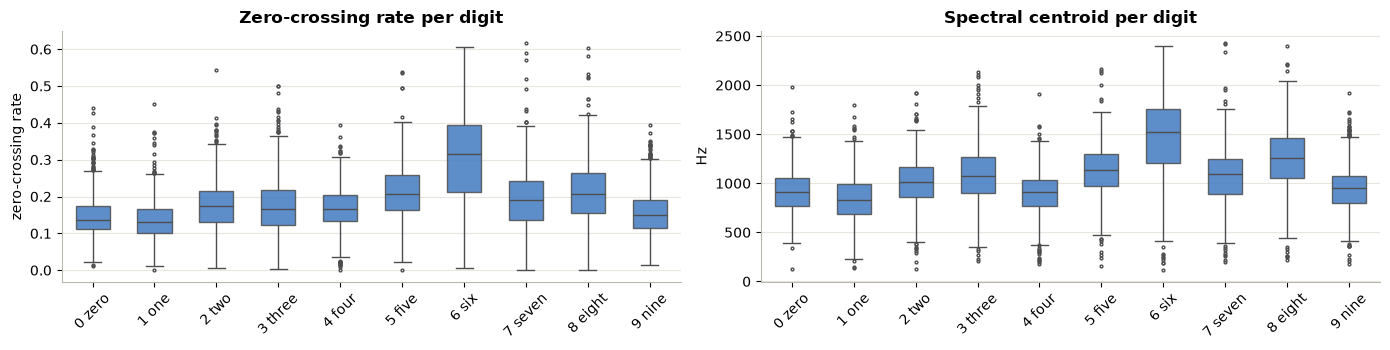

           zcr  centroid_hz
word                       
6 six    0.316     1520.911
5 five   0.207     1136.320
8 eight  0.207     1260.801
7 seven  0.190     1096.444


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
sns.boxplot(data=feats, x="word", y="zcr", order=order, color=BLUE, width=0.55, fliersize=2, linewidth=1, ax=ax[0], boxprops=dict(alpha=0.85))
ax[0].set(xlabel="", ylabel="zero-crossing rate", title="Zero-crossing rate per digit")
sns.boxplot(data=feats, x="word", y="centroid_hz", order=order, color=BLUE, width=0.55, fliersize=2, linewidth=1, ax=ax[1], boxprops=dict(alpha=0.85))
ax[1].set(xlabel="", ylabel="Hz", title="Spectral centroid per digit")
for a in ax: a.tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()
print(feats.groupby("word")[["zcr", "centroid_hz"]].median().round(3).sort_values("zcr", ascending=False).head(4))

**Interpretation.** *Six* stands far above every other digit on both charts: a median ZCR of 0.32 against 0.13 to 0.21 for the rest, and the highest spectral centroid (about 1,500 Hz). It has two *s* sounds (*s-i-k-s*), and hiss is noise-like: it crosses zero constantly and pushes energy into high frequencies. *Five* (*f*), *eight* (the burst of *t*) and *seven* (*s*) come next. Voiced digits such as *zero* and *one* sit lowest. Even though *zero* starts with a *z*, the *z* is voiced, so it crosses zero far less than *s*.

This is why a spectrogram is a good input. Hiss shows up as dark high bands, vowels as low bands, and the CNN can learn those shapes. It also predicts where the model will be confident (six) and where it may confuse digits with similar sounds.

#### Feature 3: pitch and loudness per voice. Six voices are not enough

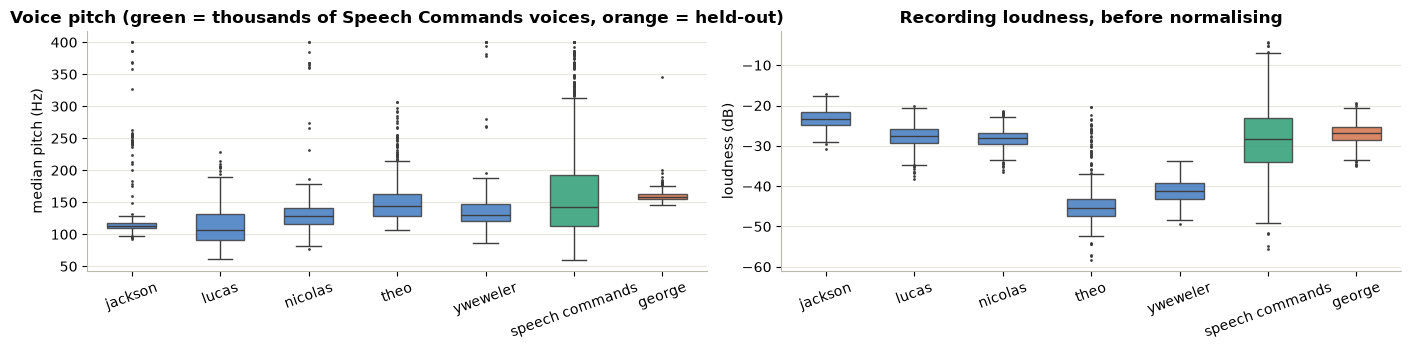

                pitch_hz               rms_db
                     10%    50%    90%    50%
voice                                        
jackson            105.2  113.1  125.0  -23.3
lucas               85.1  106.1  156.3  -27.7
nicolas            111.8  129.1  155.6  -28.2
theo               122.3  143.5  208.3  -45.4
yweweler           114.5  130.2  163.6  -41.1
speech commands     98.4  141.9  231.1  -28.2
george             152.2  158.3  169.4  -26.9


In [11]:
feats["voice"] = feats.speaker.map(voice_group)
spk_order = ["jackson", "lucas", "nicolas", "theo", "yweweler", "speech commands", "george"]
pal = {s: (ORANGE if s == "george" else AQUA if s == "speech commands" else BLUE) for s in spk_order}
fig, ax = plt.subplots(1, 2, figsize=(14, 3.6))
sns.boxplot(data=feats, x="voice", y="pitch_hz", order=spk_order, palette=pal, width=0.55, fliersize=1, linewidth=1, ax=ax[0], boxprops=dict(alpha=0.85))
ax[0].set(xlabel="", ylabel="median pitch (Hz)", title="Voice pitch (green = thousands of Speech Commands voices, orange = held-out)")
sns.boxplot(data=feats, x="voice", y="rms_db", order=spk_order, palette=pal, width=0.55, fliersize=1, linewidth=1, ax=ax[1], boxprops=dict(alpha=0.85))
ax[1].set(xlabel="", ylabel="loudness (dB)", title="Recording loudness, before normalising")
for a in ax: a.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()
print(feats.groupby("voice")[["pitch_hz", "rms_db"]].describe(percentiles=[.1, .5, .9]).loc[spk_order].round(1)[[("pitch_hz", "10%"), ("pitch_hz", "50%"), ("pitch_hz", "90%"), ("rms_db", "50%")]])

**Interpretation.** FSDD's five training voices have median pitches between about 106 Hz (lucas) and 143 Hz (theo), and the held-out george is higher than all of them, at about 158 Hz. The Speech Commands voices spread much wider: 80% of their clips fall between 98 and 231 Hz, covering both lower and higher voices than FSDD, and george's 158 Hz sits well inside that range.

This is the main story of the project: **a model trained on a few voices fails on new ones, and the fix is more voices**. Trained on FSDD alone, the CNN got 77% of george's recordings right; trained with Speech Commands as well, it gets 96% (section 4). The same logic is behind the retraining loop: when users with different voices arrive, their labelled recordings are added and the model is retrained.

Loudness also varies by more than 20 dB: theo and yweweler were recorded much more quietly (about -45 and -41 dB) than jackson (about -23 dB), and Speech Commands clips range from -39 to -19 dB. Without normalisation the model could learn "quiet = theo" instead of the digit. That's why step 3 scales every recording to the same peak.

#### Feature 4: the average spectrogram of each digit

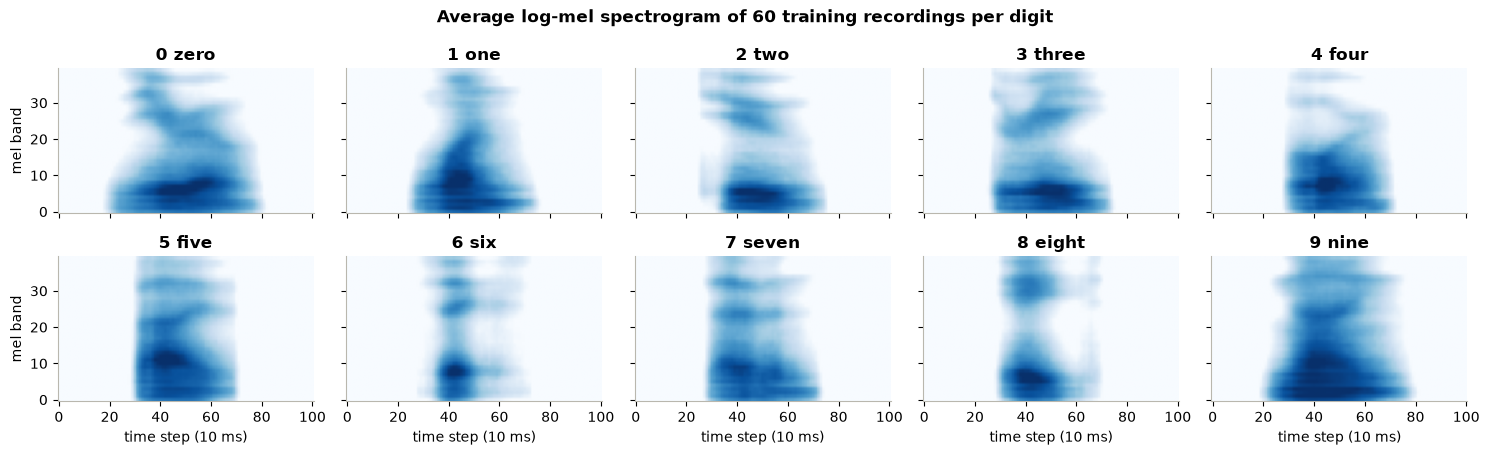

In [12]:
fig, axes = plt.subplots(2, 5, figsize=(15, 4.6), sharex=True, sharey=True)
train_files = files[files.split == "train"]
for d, a in enumerate(axes.flat):
    paths = train_files[train_files.label == d].path.head(60)
    m = np.mean([log_mel(clean(load_audio(p))[0]) for p in paths], axis=0)
    a.imshow(m, origin="lower", aspect="auto", cmap="Blues", vmin=0.25, vmax=0.9)
    a.set_title(f"{d} {DIGIT_WORDS[d]}"); a.grid(False)
for a in axes[1]: a.set_xlabel("time step (10 ms)")
for a in axes[:, 0]: a.set_ylabel("mel band")
plt.suptitle("Average log-mel spectrogram of 60 training recordings per digit", fontweight="bold")
plt.tight_layout(); plt.show()

**Interpretation.** Each digit has its own "fingerprint". *Six* has dark high bands at the start and end (the two *s* sounds) with a short vowel between them. *Seven* starts with high-band hiss, then two voiced syllables. *Zero* and *nine* are long and spread out, while *one* and *two* are short and concentrated in the low bands. These shapes are what the convolutional network learns to recognise.

### Building the model inputs

Every file goes through `prepare()`. A validation set (15% of training, stratified by digit and by voice: each FSDD speaker, and Speech Commands as one group) is held out for early stopping. Then half of the training part (never the validation part) gets a noisy copy. The test set is used only for the final scores.

In [13]:
from src.preprocessing import load_folder
from src.model import split_train_val

t0 = time.time()
X_all, y_all, rows_all = load_folder(config.TRAIN_DIR)
X_test, y_test, rows_test = load_folder(config.TEST_DIR)
X_new, y_new, rows_new = load_folder(config.NEW_VOICE_DIR)
from src.preprocessing import noisy_inputs
spk_all = np.array([r["speaker"] for r in rows_all])
grp_all = np.array(["sc" if s.startswith("sc-") else s for s in spk_all])
tr, va = split_train_val(X_all, y_all, grp_all)
rng = np.random.default_rng(SEED)
noisy = np.array([i for i in tr if rng.random() < 0.5])
X_tr = np.concatenate([X_all[tr], noisy_inputs([rows_all[i]["path"] for i in noisy])])
y_tr = np.concatenate([y_all[tr], y_all[noisy]])
X_va, y_va = X_all[va], y_all[va]
test_sc = np.array([r["speaker"].startswith("sc-") for r in rows_test])     # unseen Speech Commands voices
print(f"prepared {len(X_all) + len(X_test) + len(X_new) + len(noisy)} inputs in {time.time() - t0:.0f} s")
for name, X in [("train (with noisy copies)", X_tr), ("validation", X_va), ("test: FSDD voices", X_test[~test_sc]),
                ("test: unseen voices", X_test[test_sc]), ("new voice (george)", X_new)]:
    print(f"{name:26s} {X.shape}")

prepared 10714 inputs in 104 s
train (with noisy copies)  (8026, 40, 101, 1)
validation                 (938, 40, 101, 1)
test: FSDD voices          (250, 40, 101, 1)
test: unseen voices        (1000, 40, 101, 1)
new voice (george)         (500, 40, 101, 1)


## 3. Model creation

### Baseline: logistic regression on MFCC summaries

To know whether a CNN is worth it, start with a simple model: 20 MFCCs per frame, summarised by their mean and standard deviation over time (40 numbers per recording), then a scaled logistic regression.

In [14]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score

def mfcc_summary(rows):
    out = []
    for r in rows:
        y, _ = clean(load_audio(r["path"]))
        m = librosa.feature.mfcc(y=y, sr=SAMPLE_RATE, n_mfcc=20, n_fft=256, hop_length=80, n_mels=40)
        out.append(np.concatenate([m.mean(1), m.std(1)]))
    return np.array(out)

F_all, F_test, F_new = mfcc_summary(rows_all), mfcc_summary(rows_test), mfcc_summary(rows_new)
baseline = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, C=1.0)).fit(F_all[tr], y_all[tr])
base_scores = {}
for name, F, y in [("validation", F_all[va], y_va), ("test: FSDD voices", F_test[~test_sc], y_test[~test_sc]),
                   ("test: unseen voices", F_test[test_sc], y_test[test_sc]), ("new voice (george)", F_new, y_new)]:
    p = baseline.predict(F)
    base_scores[name] = (accuracy_score(y, p), f1_score(y, p, average="macro"))
    print(f"baseline  {name:22s} accuracy {base_scores[name][0]:.3f}  macro F1 {base_scores[name][1]:.3f}")

baseline  validation             accuracy 0.664  macro F1 0.664
baseline  test: FSDD voices      accuracy 0.880  macro F1 0.878
baseline  test: unseen voices    accuracy 0.623  macro F1 0.622
baseline  new voice (george)     accuracy 0.452  macro F1 0.400


### The CNN

A small convolutional network reads the 40 × 101 spectrogram like a one-channel image (`src/model.py`):

- four Conv2D blocks (16 → 32 → 64 → 64 filters, 3×3) with **batch normalisation** and ReLU, and max-pooling after the first three
- global average pooling, then **dropout 0.3**, a 64-unit dense layer with **L2 weight decay** (1e-4), dropout 0.3, and a 10-way softmax

How the training is kept from overfitting:

| Technique | Setting |
|---|---|
| Optimiser | Adam, learning rate 1e-3 |
| Learning-rate schedule | halve when validation loss stalls for 3 epochs (ReduceLROnPlateau) |
| Early stopping | patience 8 on validation loss (up to 50 epochs), keep the best weights |
| Data augmentation | each batch, fresh: random time shift (±80 ms) plus one frequency mask (up to 6 bands) and one time mask (up to 100 ms), SpecAugment style |
| Regularisation | batch norm, dropout 0.3 (×2), L2 1e-4 |

One setting needed fixing. With the Keras default batch-norm momentum (0.99), a first run's validation accuracy stayed at 10% (chance) while training accuracy climbed, and early stopping ended it after 7 epochs. With only 30 batches per epoch, the running averages that batch norm uses at prediction time lagged far behind. Momentum 0.9 fixes it.

In [15]:
from src import model as M
M.set_seed(SEED)
M.build_model().summary()

Model: "digit_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ log_mel (InputLayer)            │ (None, 40, 101, 1)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 40, 101, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 40, 101, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 40, 101, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 20, 50, 32)     │         4,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 20, 50, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 20, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 25, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 25, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_2 (Activation)       │ (None, 10, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 12, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 5, 12, 64)      │        36,864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 5, 12, 64)      │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_3 (Activation)       │ (None, 5, 12, 64)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ digit (Dense)                   │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,562 (256.10 KB)

 Trainable params: 65,210 (254.73 KB)

 Non-trainable params: 352 (1.38 KB)

In [16]:
t0 = time.time()
M.set_seed(SEED)
cnn, history = M.train(X_tr, y_tr, X_va, y_va, epochs=50, batch_size=64, lr=1e-3, patience=8, verbose=2)
train_seconds = time.time() - t0
print(f"trained for {len(history['loss'])} epochs in {train_seconds:.0f} s; best validation loss at epoch {int(np.argmin(history['val_loss'])) + 1}")

Epoch 1/50


126/126 - 54s - 429ms/step - accuracy: 0.2113 - loss: 2.1472 - val_accuracy: 0.2633 - val_loss: 1.9446 - learning_rate: 0.0010


Epoch 2/50


126/126 - 32s - 254ms/step - accuracy: 0.3950 - loss: 1.6928 - val_accuracy: 0.6311 - val_loss: 1.2662 - learning_rate: 0.0010


Epoch 3/50


126/126 - 31s - 247ms/step - accuracy: 0.5152 - loss: 1.3826 - val_accuracy: 0.7228 - val_loss: 0.9305 - learning_rate: 0.0010


... (91 outputs left out)

126/126 - 23s - 180ms/step - accuracy: 0.9297 - loss: 0.2593 - val_accuracy: 0.9531 - val_loss: 0.1840 - learning_rate: 1.2500e-04


Epoch 50/50


126/126 - 23s - 185ms/step - accuracy: 0.9343 - loss: 0.2571 - val_accuracy: 0.9531 - val_loss: 0.1895 - learning_rate: 1.2500e-04


trained for 50 epochs in 1759 s; best validation loss at epoch 47


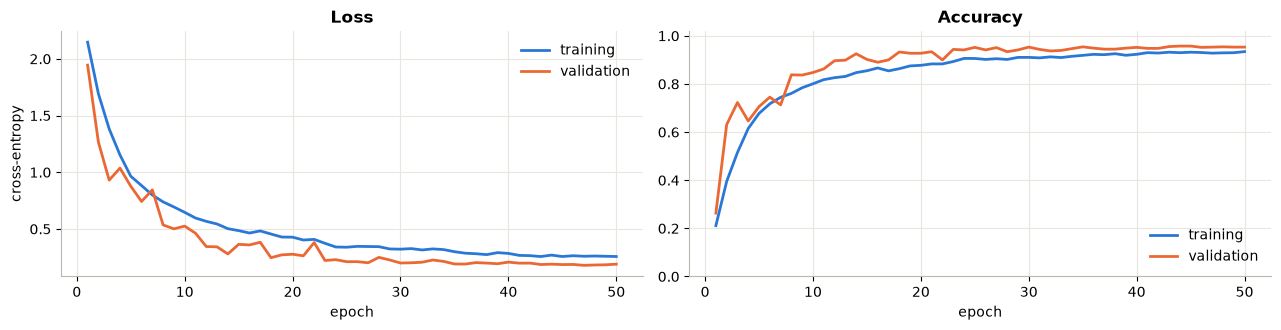

In [17]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.4))
ep = np.arange(1, len(history["loss"]) + 1)
ax[0].plot(ep, history["loss"], color=BLUE, lw=2, label="training"); ax[0].plot(ep, history["val_loss"], color=ORANGE, lw=2, label="validation")
ax[0].set(title="Loss", xlabel="epoch", ylabel="cross-entropy"); ax[0].legend(frameon=False)
ax[1].plot(ep, history["accuracy"], color=BLUE, lw=2, label="training"); ax[1].plot(ep, history["val_accuracy"], color=ORANGE, lw=2, label="validation")
ax[1].set(title="Accuracy", xlabel="epoch", ylim=(0, 1.02)); ax[1].legend(frameon=False)
plt.tight_layout(); plt.show()

Training accuracy is measured on augmented batches (masks, shifts and noisy copies), so it can sit *below* validation accuracy. That's expected: the augmentation makes training harder on purpose.

## 4. Model testing

All metrics on the untouched test set, reported separately for its two parts. **FSDD voices** are other takes by speakers the model trained on (the easy case). **Unseen voices** are Speech Commands speakers who are not in the training data at all, the realistic case for a new user. Metrics: accuracy, macro precision, recall and F1, log loss, one-vs-rest ROC AUC, a per-digit report and confusion matrices.

In [18]:
from sklearn.metrics import classification_report
test_metrics = M.evaluate(cnn, X_test, y_test)
fsdd_metrics = M.evaluate(cnn, X_test[~test_sc], y_test[~test_sc])
unseen_metrics = M.evaluate(cnn, X_test[test_sc], y_test[test_sc])
new_metrics = M.evaluate(cnn, X_new, y_new)
val_metrics = M.evaluate(cnn, X_va, y_va)
keys = ["accuracy", "precision_macro", "recall_macro", "f1_macro", "log_loss", "roc_auc_ovr"]
table = pd.DataFrame({"validation": [val_metrics.get(k) for k in keys],
                      "test: all 1,250": [test_metrics.get(k) for k in keys],
                      "test: FSDD voices": [fsdd_metrics.get(k) for k in keys],
                      "test: unseen voices": [unseen_metrics.get(k) for k in keys],
                      "new voice (george)": [new_metrics.get(k) for k in keys]}, index=keys).round(4)
proba_unseen = M.predict_proba(cnn, X_test[test_sc])
sure = proba_unseen.max(1) >= 0.85
print(f"unseen voices: {sure.mean():.0%} of answers come with 85%+ confidence; "
      f"those are right {np.mean(proba_unseen.argmax(1)[sure] == y_test[test_sc][sure]):.0%} of the time")
table

unseen voices: 90% of answers come with 85%+ confidence; those are right 99% of the time


,validation,"test: all 1,250",test: FSDD voices,test: unseen voices,new voice (george)
accuracy,0.9531,0.9560,0.9920,0.9470,0.9580
precision_macro,0.9540,0.9562,0.9926,0.9475,0.9615
recall_macro,0.9530,0.9560,0.9920,0.9470,0.9580
f1_macro,0.9531,0.9559,0.9920,0.9469,0.9580
log_loss,0.1384,0.1662,0.0163,0.2037,0.1367
roc_auc_ovr,0.9989,0.9981,1.0000,0.9974,0.9992


In [19]:
pred_unseen = proba_unseen.argmax(1)
print("Unseen voices (Speech Commands test speakers):")
print(classification_report(y_test[test_sc], pred_unseen, target_names=[f"{d} {w}" for d, w in enumerate(DIGIT_WORDS)], digits=3))

Unseen voices (Speech Commands test speakers):


              precision    recall  f1-score   support

      0 zero      0.941     0.950     0.945       100
       1 one      0.959     0.940     0.949       100
       2 two      0.941     0.960     0.950       100
     3 three      0.942     0.980     0.961       100
      4 four      0.914     0.960     0.937       100
      5 five      0.937     0.890     0.913       100
       6 six      0.931     0.950     0.941       100
     7 seven      0.989     0.920     0.953       100
     8 eight      0.960     0.950     0.955       100
      9 nine      0.960     0.970     0.965       100

    accuracy                          0.947      1000
   macro avg      0.948     0.947     0.947      1000
weighted avg      0.948     0.947     0.947      1000



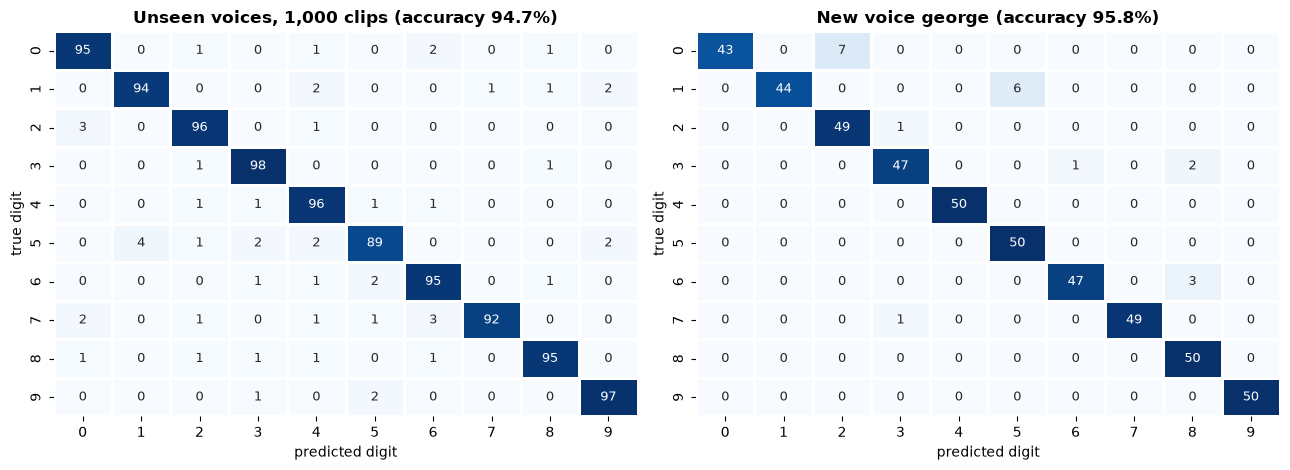

In [20]:
pred_new = M.predict_proba(cnn, X_new).argmax(1)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for a, cm, title in [(ax[0], unseen_metrics["confusion_matrix"], f"Unseen voices, 1,000 clips (accuracy {unseen_metrics['accuracy']:.1%})"),
                     (ax[1], new_metrics["confusion_matrix"], f"New voice george (accuracy {new_metrics['accuracy']:.1%})")]:
    sns.heatmap(np.array(cm), annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, linewidths=1, linecolor="white",
                xticklabels=range(10), yticklabels=range(10), annot_kws={"size": 9})
    a.set(title=title, xlabel="predicted digit", ylabel="true digit")
plt.tight_layout(); plt.show()

### Baseline vs CNN

In [21]:
compare = pd.DataFrame({
    "model": ["Logistic regression on MFCC summaries", "CNN on log-mel spectrograms"],
    "FSDD voices": [base_scores["test: FSDD voices"][0], fsdd_metrics["accuracy"]],
    "unseen voices": [base_scores["test: unseen voices"][0], unseen_metrics["accuracy"]],
    "unseen voices macro F1": [base_scores["test: unseen voices"][1], unseen_metrics["f1_macro"]],
    "george": [base_scores["new voice (george)"][0], new_metrics["accuracy"]],
}).round(3)
compare

,model,FSDD voices,unseen voices,unseen voices macro F1,george
0,Logistic regression on MFCC summaries,0.880,0.623,0.622,0.452
1,CNN on log-mel spectrograms,0.992,0.947,0.947,0.958


**What the numbers say.**

- **FSDD voices** (other takes by speakers in training) are the easy case: the CNN gets 99.2%, the baseline 88.0%.
- **Unseen voices** (1,000 clips from Speech Commands speakers who are not in the training data) are the realistic case for a new user. The CNN gets **94.7%**, the baseline 62.3%: looking at the shape of the spectrogram over time generalises far better than averaging features over the clip.
- **Confidence:** on unseen voices, 90% of the CNN's answers come with at least 85% confidence, and those answers are right 99% of the time. When the model is sure, it is almost always right; when it isn't, an app could ask the user to say the digit again.
- **george:** 95.8%, against 76.8% for the first version of this model, which was trained on FSDD's five voices only. Adding thousands of voices helped a new speaker more than anything else tried.
- The weakest digit on unseen voices is *five* (recall 0.89); every digit is above 0.9 F1.

## Prediction functions

`src/prediction.py` wraps the saved model: give it a path (or bytes from an upload) and it returns the digit, its word and the probability of every digit. First the model is saved, so the predictor loads exactly the file the API will serve.

In [22]:
info = {
    "version": 1, "created_at": time.strftime("%Y-%m-%dT%H:%M:%SZ", time.gmtime()), "mode": "notebook",
    "data": {"train_rows": int(len(X_tr)), "noisy_copies": int(len(noisy)), "val_rows": int(len(X_va)),
             "test_rows": int(len(X_test)), "sources": ["FSDD v1.0.10", "Speech Commands v0.02 (digits)"],
             "held_out_speaker": "george"},
    "training_seconds": round(train_seconds, 1),
    "test_metrics": test_metrics, "test_fsdd_metrics": fsdd_metrics, "test_unseen_metrics": unseen_metrics,
    "new_voice_metrics": new_metrics, "history": history,
}
M.save(cnn, config.BASE_MODEL_PATH, info)
print("saved", config.BASE_MODEL_PATH, f"({config.BASE_MODEL_PATH.stat().st_size / 1024:.0f} KB)")
print("saved", config.BASE_MODEL_INFO)

saved C:\Users\user\Documents\voice-digits-pipeline\models\digit_cnn.h5 (855 KB)
saved C:\Users\user\Documents\voice-digits-pipeline\models\digit_cnn_info.json


In [23]:
from src.prediction import Predictor
predictor = Predictor()
examples = ["data/test/3/3_lucas_2.wav", "data/test/6/6_nicolas_0.wav",
            *[sorted(config.TEST_DIR.glob(f"{d}/{d}_sc-*.wav"))[0].relative_to(ROOT).as_posix() for d in (4, 5, 8)],
            "data/new_voice/0/0_george_7.wav", "data/new_voice/5/5_george_33.wav"]
rows = []
for p in examples:
    t0 = time.perf_counter()
    r = predictor.predict_file(p)
    rows.append({"file": p, "true": int(Path(p).parent.name), "predicted": r["digit"], "word": r["word"],
                 "confidence": round(r["confidence"], 3), "ms": round((time.perf_counter() - t0) * 1000, 1)})
pd.DataFrame(rows)

,file,true,predicted,word,confidence,ms
0,data/test/3/3_lucas_2.wav,3,3,three,1.000,100.7
1,data/test/6/6_nicolas_0.wav,6,6,six,0.997,46.2
2,data/test/4/4_sc-0c40e715_0.wav,4,4,four,0.878,15.3
3,data/test/5/5_sc-0aad3227_0.wav,5,5,five,0.987,30.7
4,data/test/8/8_sc-0cb74144_4.wav,8,8,eight,0.996,14.4
5,data/new_voice/0/0_george_7.wav,0,0,zero,0.997,27.0
6,data/new_voice/5/5_george_33.wav,5,5,five,0.901,18.6


## 5. Retraining

### The trigger

In production, users upload labelled recordings (in bulk, or by correcting a wrong prediction). `src/retrain.py` calls for retraining when **either**

1. at least **100** new recordings are waiting, or
2. the live model gets fewer than **85%** of the waiting recordings right (checked once at least 20 are in).

The second rule is the important one. It measures the model on exactly the voices users bring, so it catches the "new voice" problem early. Here it is applied to 400 of george's recordings (takes 10 to 49), as if george's users had uploaded them. Takes 0 to 9 (100 recordings) stay aside to check the result.

In [24]:
take_new = np.array([r["take"] for r in rows_new])
up, check = take_new >= 10, take_new < 10
acc_uploads = M.accuracy(cnn, X_new[up], y_new[up])
reasons = []
if up.sum() >= config.RETRAIN_MIN_NEW_SAMPLES:
    reasons.append(f"{up.sum()} new recordings waiting (limit {config.RETRAIN_MIN_NEW_SAMPLES})")
if acc_uploads < config.RETRAIN_ACCURACY_TRIGGER:
    reasons.append(f"live model gets {acc_uploads:.1%} of them right (below {config.RETRAIN_ACCURACY_TRIGGER:.0%})")
print("trigger fired:", bool(reasons))
for r in reasons: print(" -", r)

trigger fired: True
 - 400 new recordings waiting (limit 100)


### Fine-tuning the saved model

Retraining doesn't start from random weights. It **loads the saved model and keeps training it** (fine-tuning, i.e. the current model is the pre-trained starting point):

- learning rate 3e-4 (lower than the first training, so it adjusts instead of starting over)
- trained on the original training data **plus** the uploads, so it doesn't forget the voices it knows. Each upload counts up to 5×, so a small upload isn't drowned out by the 6,250 originals. (The app's job also adds noisy copies; this demonstration skips them to save time.)
- the same augmentation, early stopping (patience 4, up to 15 epochs) and learning-rate schedule as before

The app then applies a **promotion rule**: the new model goes live only if its test accuracy drops by no more than 2 points *and* it is not worse on recordings held aside from the uploads. Otherwise the old model stays live.

In [25]:
base = M.load(config.BASE_MODEL_PATH)              # the saved model is the starting point
X_up, y_up = X_new[up], y_new[up]
w_up = float(np.clip(len(X_all) / (4 * len(X_up)), 1, 5))
X_mix = np.concatenate([X_all, X_up]); y_mix = np.concatenate([y_all, y_up])
groups = np.concatenate([grp_all, np.array(["george"] * len(X_up))])
w_mix = np.concatenate([np.ones(len(X_all)), np.full(len(X_up), w_up)]).astype("float32")
tr2, va2 = split_train_val(X_mix, y_mix, groups)

before = {"test": M.accuracy(base, X_test, y_test), "george (held aside)": M.accuracy(base, X_new[check], y_new[check])}
t0 = time.time()
M.set_seed(SEED)
tuned, history2 = M.fine_tune(base, X_mix[tr2], y_mix[tr2], X_mix[va2], y_mix[va2], sample_weight=w_mix[tr2],
                              epochs=15, lr=3e-4, patience=4, verbose=2)
after = {"test": M.accuracy(tuned, X_test, y_test), "george (held aside)": M.accuracy(tuned, X_new[check], y_new[check])}
print(f"upload weight {w_up:.2f}; fine-tuned for {len(history2['loss'])} epochs in {time.time() - t0:.0f} s")

Epoch 1/15


89/89 - 26s - 296ms/step - accuracy: 0.9255 - loss: 0.3275 - val_accuracy: 0.9599 - val_loss: 0.1808 - learning_rate: 3.0000e-04


Epoch 2/15


89/89 - 17s - 191ms/step - accuracy: 0.9324 - loss: 0.2910 - val_accuracy: 0.9489 - val_loss: 0.1962 - learning_rate: 3.0000e-04


Epoch 3/15


89/89 - 17s - 186ms/step - accuracy: 0.9337 - loss: 0.2838 - val_accuracy: 0.9629 - val_loss: 0.1640 - learning_rate: 3.0000e-04


... (21 outputs left out)

89/89 - 17s - 189ms/step - accuracy: 0.9427 - loss: 0.2352 - val_accuracy: 0.9649 - val_loss: 0.1416 - learning_rate: 7.5000e-05


Epoch 15/15


89/89 - 16s - 184ms/step - accuracy: 0.9462 - loss: 0.2322 - val_accuracy: 0.9669 - val_loss: 0.1417 - learning_rate: 7.5000e-05


upload weight 3.91; fine-tuned for 15 epochs in 268 s


,test,george (held aside),promote?
before retraining,0.956,1.0,None
after retraining,0.958,1.0,True


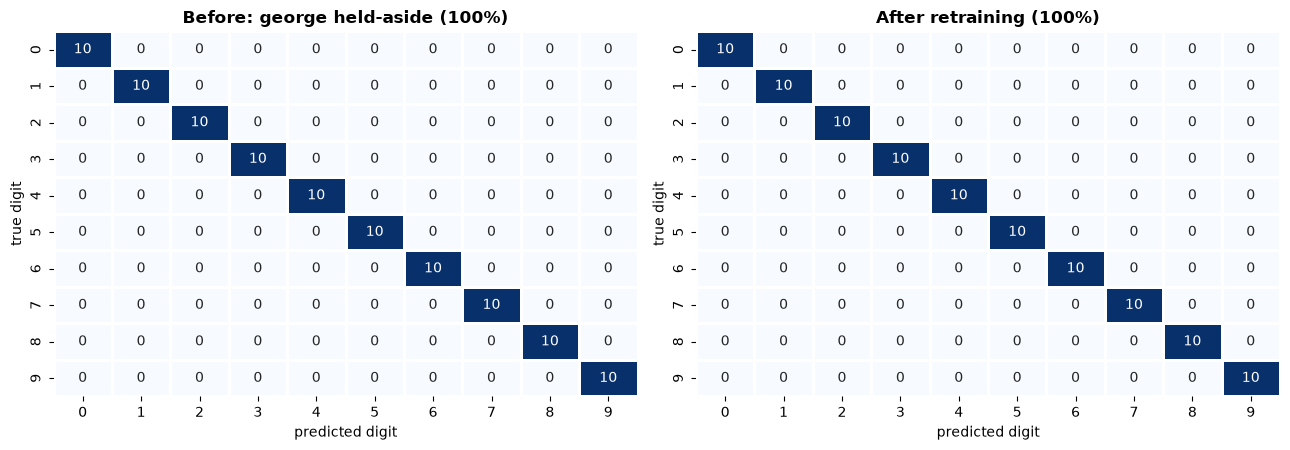

In [26]:
res = pd.DataFrame({"before retraining": before, "after retraining": after}).T
res["promote?"] = [None, (after["test"] >= before["test"] - config.MAX_TEST_DROP) and (after["george (held aside)"] >= before["george (held aside)"])]
display(res.round(3))

tuned_check = M.evaluate(tuned, X_new[check], y_new[check])
base_check = M.evaluate(M.load(config.BASE_MODEL_PATH), X_new[check], y_new[check])   # fine_tune changed `base` in place
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
for a, m, title in [(ax[0], base_check, f"Before: george held-aside ({base_check['accuracy']:.0%})"),
                    (ax[1], tuned_check, f"After retraining ({tuned_check['accuracy']:.0%})")]:
    sns.heatmap(np.array(m["confusion_matrix"]), annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, linewidths=1,
                linecolor="white", xticklabels=range(10), yticklabels=range(10))
    a.set(title=title, xlabel="predicted digit", ylabel="true digit")
plt.tight_layout(); plt.show()

With Speech Commands in training, version 1 already gets all 100 of george's held-aside recordings right, so here the trigger fires only on the count rule (400 waiting), and retraining has little left to fix on george. Held-aside stays at 100% and the whole test set goes from 95.6% to 95.8%. The promotion rule passes, so the new model would go live.

The loop matters for voices the model still finds hard. In the app, the **My voice** tab tests the model on the user's own voice, records labelled clips, and starts this same fine-tuning on them.

The fine-tuned model is **not** saved over `models/digit_cnn.h5`. That file stays as version 1, the starting point of the app. In the app the same steps run when someone presses **Retrain now** (or automatically, with `AUTO_RETRAIN=1`), and each result is saved as a new version in `storage/models/`, logged in the database and shown on the dashboard.

## Summary

In [27]:
summary = pd.DataFrame([
    ["MFCC + logistic regression (baseline)", base_scores["test: FSDD voices"][0], base_scores["test: unseen voices"][0], base_scores["new voice (george)"][0], None],
    ["CNN, saved as models/digit_cnn.h5 (v1)", fsdd_metrics["accuracy"], unseen_metrics["accuracy"], new_metrics["accuracy"], before["george (held aside)"]],
    ["CNN after retraining on george's uploads", None, None, None, after["george (held aside)"]],
], columns=["model", "test: FSDD voices", "test: unseen voices", "george, all 500", "george, 100 held aside"])
print(f"whole test set after retraining: {before['test']:.3f} -> {after['test']:.3f}")
summary.round(3)

whole test set after retraining: 0.956 -> 0.958


,model,test: FSDD voices,test: unseen voices,"george, all 500","george, 100 held aside"
0,MFCC + logistic regression (baseline),0.880,0.623,0.452,NaN
1,"CNN, saved as models/digit_cnn.h5 (v1)",0.992,0.947,0.958,1.0
2,CNN after retraining on george's uploads,NaN,NaN,NaN,1.0


**Limitations.**

- Both datasets are English words. Real mobile-money users would speak Kinyarwanda, Swahili or French, on cheap phones, in noisy places. The pipeline (upload labelled recordings, retrain, promote only if not worse) is how the model would be adapted, but it needs those recordings first.
- A single new person's voice can still be hard: the **My voice** tab in the app tests the model on the user's own voice and records labelled clips for retraining on it.
- The model recognises one isolated digit per recording. A real amount needs a sequence of digits; that would need splitting a recording into words or a sequence model.
- Speaking a PIN aloud isn't private, so this should be used for amounts and phone numbers, never for PINs.